## Deliverable 1
#### Amalie K. Meltvedt and Maren J. Borgaas
#### Date: 15.10.2016

### Importing the necessary libraries

In [9]:
# Libraries needed (pandas is not standard and must be installed in Python)
import requests
import pandas as pd
import os
import matplotlib.pyplot as plt
# fra chat
from dotenv import load_dotenv

### Task 1

The client ID is loaded from an environment file to access frost API. Defines the parameters to retrieve air temperatur data for 2025 for this task. 

In [10]:
load_dotenv()
client_id = os.getenv("MET_CLIENT_ID")

# From the task description
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

Sending a HTTP GET request to frost API with the defined parameters and client-ID. Converts the response to json data. Tests whether the request was successfull.

In [11]:

# From the example code
# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
json = r.json()

# From the example code
# Check if the request worked, print out any errors
if r.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no!')

else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])


Data retrieved from frost.met.no!


The request was successfull and the data was retrieved.

Observation dates and temperatures are extracted from json and stored in a dataframe. Furthermore, the dates are converted to datetime objects for plotting.

In [12]:
df = pd.DataFrame([
    {
        "date": entry["referenceTime"],
        "temperature": observation["value"]
    }
    for entry in data
    for observation in entry["observations"]
    if observation["timeOffset"] == "PT0H"
    ])

# Convert the dates to datetime objects
df["date"] = pd.to_datetime(df["date"])

Making a line plot to visualise the daily mean temperatures throughout 2025 in Ås. Labels the axes and formating to improve readability.

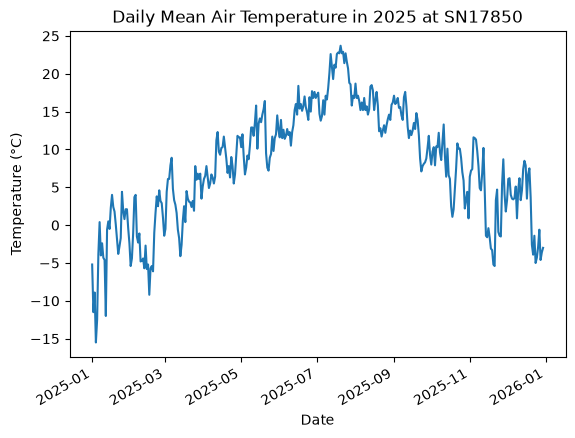

In [13]:
# Making the plot
fig, ax = plt.subplots()
ax.plot(df["date"], df["temperature"])

# Formatting the plot
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Daily Mean Air Temperature in 2025 at SN17850")

# Make the x-axis labels more readable
fig.autofmt_xdate()

# Show the plot
plt.show()

The plot shows that the temperatures varies quite a lot within the months, and it varies between the months as one would expect. The highest temperatures are found in July, and the lowest are found in January.

Calculates the summary statistics for 2025 in a summary table, including mean, median, min and max temperatures.

In [3]:
# Making a summary table 
summary_table = df[["temperature"]].agg(["mean", "median", "min", "max"]).round(2)
print("\nSummary Table:")
print(summary_table)


Summary Table:
        temperature
mean            7.9
median          8.4
min           -15.5
max            23.7


The summary table gives that the lowest temperature for 2025 was -15,5 and the highest was 23,7. The mean temperature was 7,9. 